In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler,LabelEncoder

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import math

import joblib
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/Flight_Prediction_Clean_Dataset.csv')

In [ ]:
df

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...,...,...
300148,300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585


In [ ]:
df.drop(['Unnamed: 0'],axis =1 , inplace= True)

In [ ]:
df

,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...,...
300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585


In [ ]:
df.drop(['flight'],axis=1,inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  object 
 1   source_city       300153 non-null  object 
 2   departure_time    300153 non-null  object 
 3   stops             300153 non-null  object 
 4   arrival_time      300153 non-null  object 
 5   destination_city  300153 non-null  object 
 6   class             300153 non-null  object 
 7   duration          300153 non-null  float64
 8   days_left         300153 non-null  int64  
 9   price             300153 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 22.9+ MB


In [ ]:
df.airline.unique()

array(['SpiceJet', 'AirAsia', 'Vistara', 'GO_FIRST', 'Indigo',
       'Air_India'], dtype=object)

In [ ]:
df.source_city.unique()

array(['Delhi', 'Mumbai', 'Bangalore', 'Kolkata', 'Hyderabad', 'Chennai'],
      dtype=object)

In [ ]:
print('DepartureTime -> :',df.departure_time.unique(),'\n')
print('Stops -> ',df.stops.unique(),'\n')
print('Arrival Time -> :',df.arrival_time.unique(),'\n')
print('Destination City -> :',df.destination_city.unique(),'\n')
print('Class -> :',df['class'].unique(),'\n')

print('Days Left -> :',df.days_left.unique(),'\n')

DepartureTime -> : ['Evening' 'Early_Morning' 'Morning' 'Afternoon' 'Night' 'Late_Night'] 

Stops ->  ['zero' 'one' 'two_or_more'] 

Arrival Time -> : ['Night' 'Morning' 'Early_Morning' 'Afternoon' 'Evening' 'Late_Night'] 

Destination City -> : ['Mumbai' 'Bangalore' 'Kolkata' 'Hyderabad' 'Chennai' 'Delhi'] 

Class -> : ['Economy' 'Business'] 

Days Left -> : [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49] 



In [ ]:
df.stops = df.stops.replace("zero", 0).replace("one", 1).replace('two_or_more',2)

In [ ]:
print('Stops -> ',df.stops.unique(),'\n')

Stops ->  [0 1 2] 



In [ ]:
df.describe()

,stops,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,0.924312,12.221021,26.004751,20889.660523
std,0.398106,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,1.000000,6.830000,15.000000,4783.000000
50%,1.000000,11.250000,26.000000,7425.000000
75%,1.000000,16.170000,38.000000,42521.000000
max,2.000000,49.830000,49.000000,123071.000000


In [ ]:
df.shape

(300153, 10)

In [ ]:
df.isnull().sum()

,0
airline,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
class,0
duration,0
days_left,0
price,0


In [ ]:
df.duplicated().sum()

np.int64(2213)

In [ ]:
df.select_dtypes('object').columns.to_list()

['airline',
 'source_city',
 'departure_time',
 'arrival_time',
 'destination_city',
 'class']

In [ ]:
category_col = df.select_dtypes(include='object').columns

for col in category_col:
    df[col] = df[col].str.strip()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  object 
 1   source_city       300153 non-null  object 
 2   departure_time    300153 non-null  object 
 3   stops             300153 non-null  int64  
 4   arrival_time      300153 non-null  object 
 5   destination_city  300153 non-null  object 
 6   class             300153 non-null  object 
 7   duration          300153 non-null  float64
 8   days_left         300153 non-null  int64  
 9   price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(6)
memory usage: 22.9+ MB


In [ ]:
df.groupby('airline')['price'].mean()

,price
airline,
AirAsia,4091.072742
Air_India,23507.019112
GO_FIRST,5652.007595
Indigo,5324.216303
SpiceJet,6179.278881
Vistara,30396.536302


In [ ]:
df[df['price']>42521]['price'].shape

(74379,)

In [ ]:
df[df['price']<0]['price'].shape

(0,)

# EDA

airline


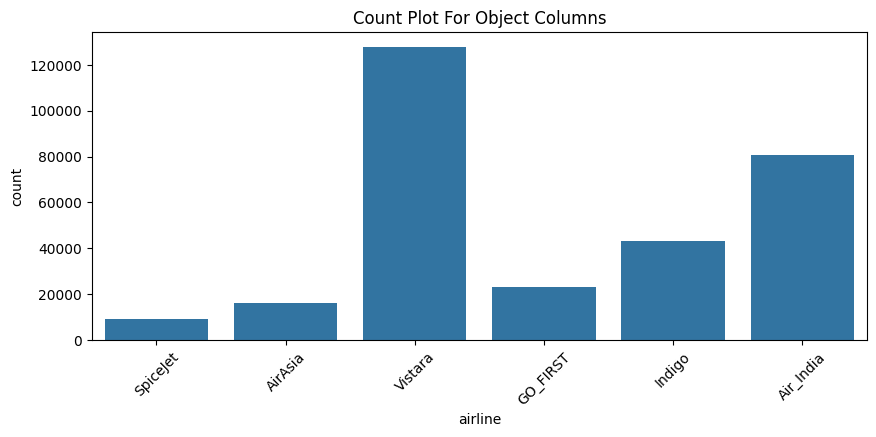

departure_time


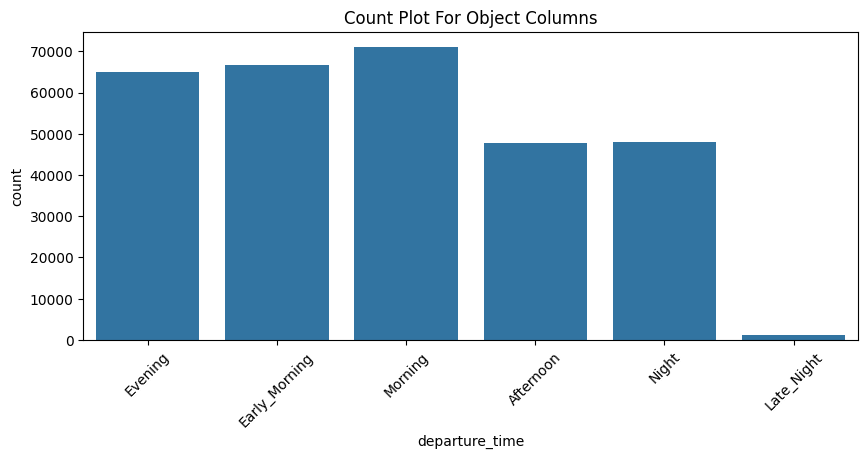

arrival_time


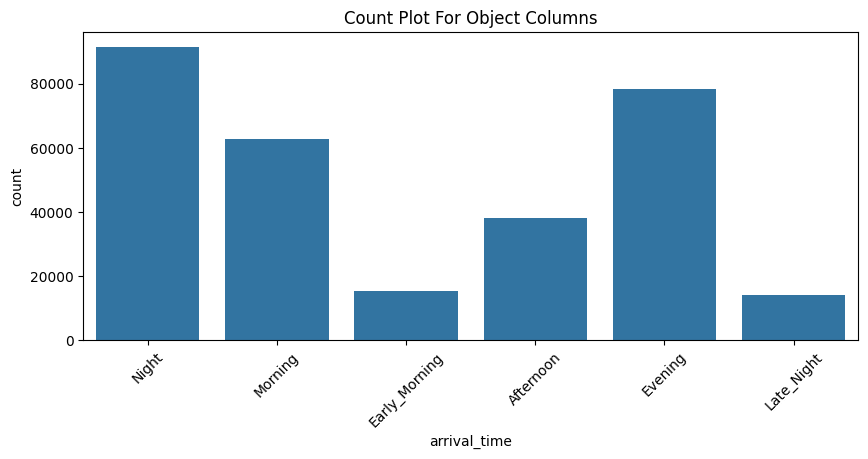

source_city


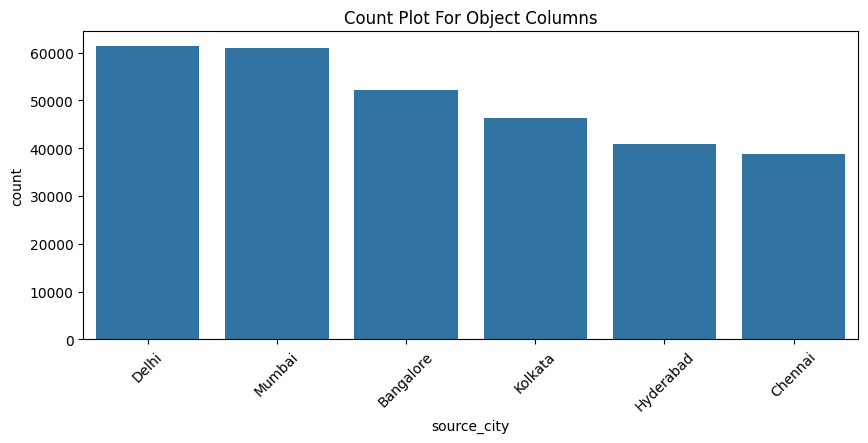

destination_city


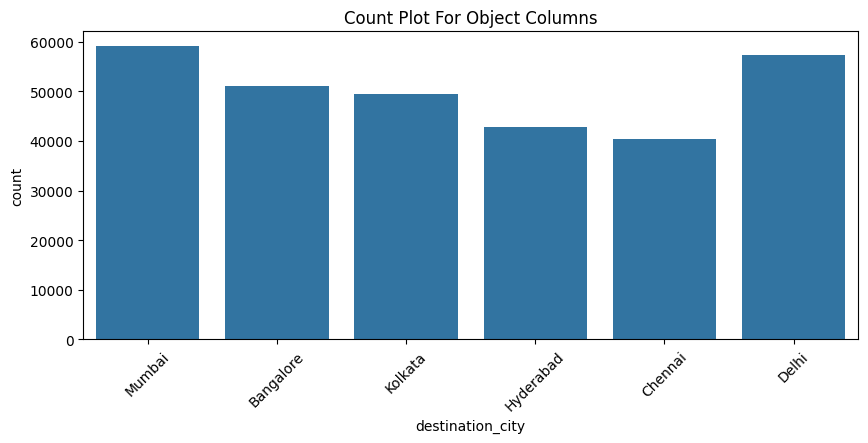

class


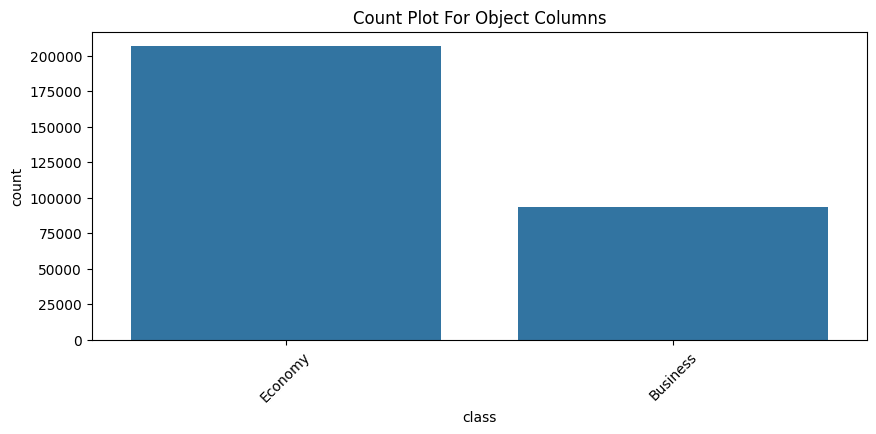

In [ ]:
object_columns = ['airline',
 'departure_time',
 'arrival_time',
 'source_city',
 'destination_city',
 'class']
for i in object_columns:
  print(i)
  plt.figure(figsize=(10,4))
  sns.countplot(x=df[i])
  plt.xticks(rotation = 45)
  plt.title('Count Plot For Object Columns')
  plt.show()

 People mostly booked thier flight in Vistara and Airindia Lowest bookin is

1. People mostly booked thier flight in Vistara and Airindia Lowest bookin is Spicejet.
2. most people prefere Morning , Early Morning , Evening , and lowest is late night Departure Time.
3. Most people Arrival time is Night , Evening lowest is Early Morning
4. Most of People Booked Flight from Delhi, Mumbai.
5. Most peoples destintion is Delhi, Mumbai , banglore, kolkata
5. Pepole prefer Economy class than Business class



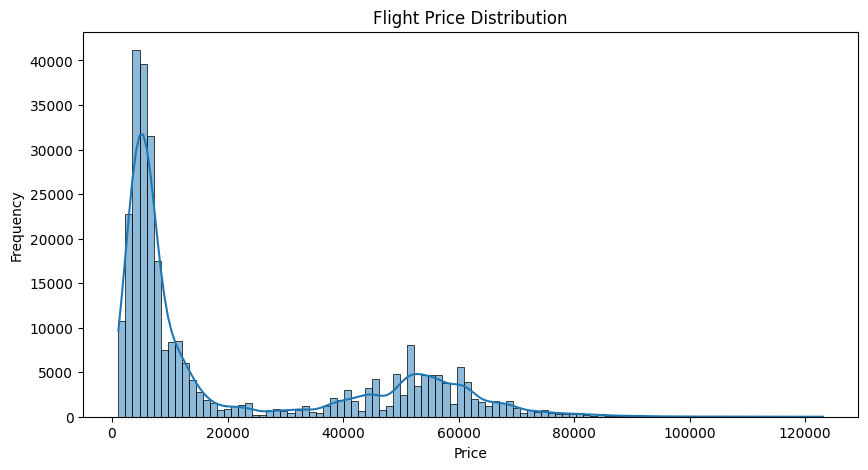

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='price',
    bins=100,
    kde=True
)
plt.title('Flight Price Distribution')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

1. There are two clusters first one show us the values from 5 - 20 k are this suggests that lower-priced tickets are the most common.
2. The 2 cluster shows values distrubuted from 40 - 60 k indicating first class tickets or tickets booked from Vistara or Airindia flights
3. it is Right Skew with a long tail extending toward expensive tickets that reach up to 1 lack.


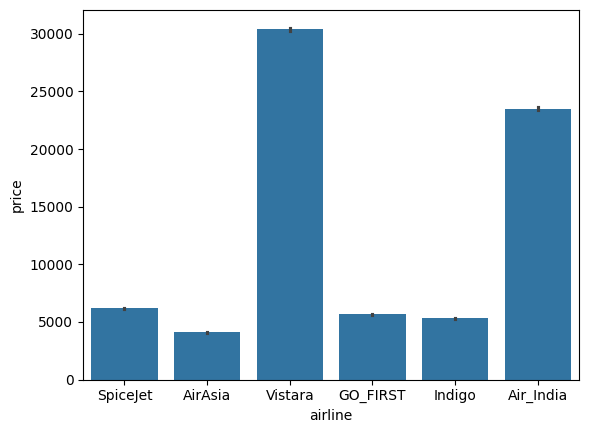

In [ ]:
sns.barplot(x='airline',y = 'price' ,data = df)
plt.show()

Here we can see Vistara is most expensive with prices slightly above 30,000
Air_India is at around 23,000 the lowest  is AirAsia,

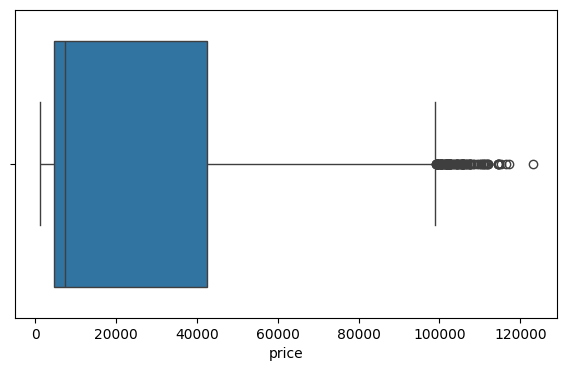

In [ ]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=df['price'])
plt.show()

price is distrubuted between 5 to 40k and there are outliers which crosses the 1 lac to 1 lac 20

In [ ]:
df.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,Evening,0,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,Delhi,Early_Morning,0,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,Delhi,Early_Morning,0,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,Delhi,Morning,0,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,Delhi,Morning,0,Morning,Mumbai,Economy,2.33,1,5955


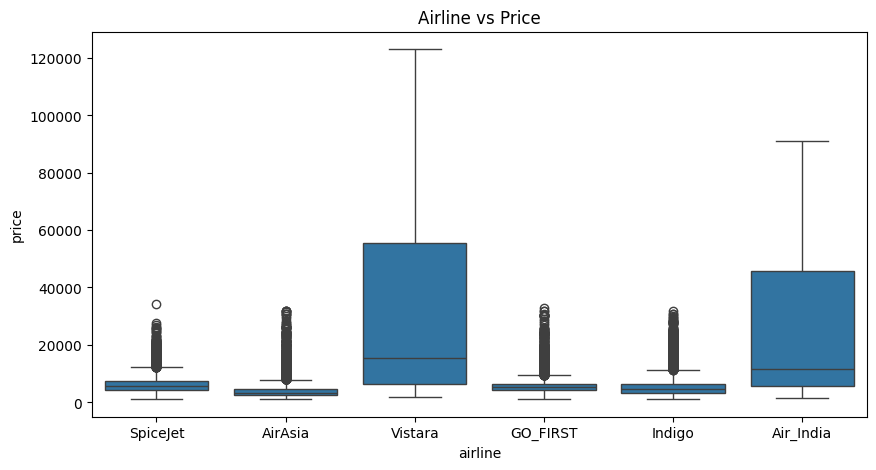

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(x="airline",y="price", data=df)
plt.title("Airline vs Price")
plt.show()

Vistara and Air India Both show much higher median prices and wider spreads, meaning they not only charge more on average but also have greater variability in fares.

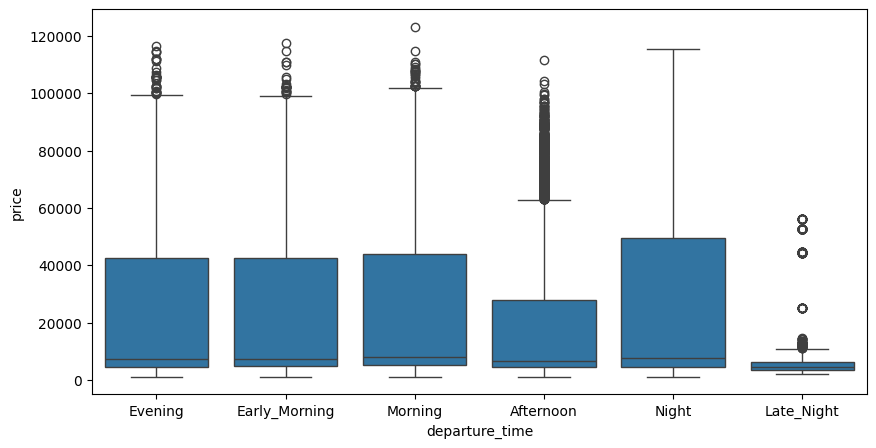

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(x="departure_time",y="price", data=df)
plt.show()

1. Late Night -> Generally the Cheapest
2. Morning and evening Flights have higher median price and more outlier


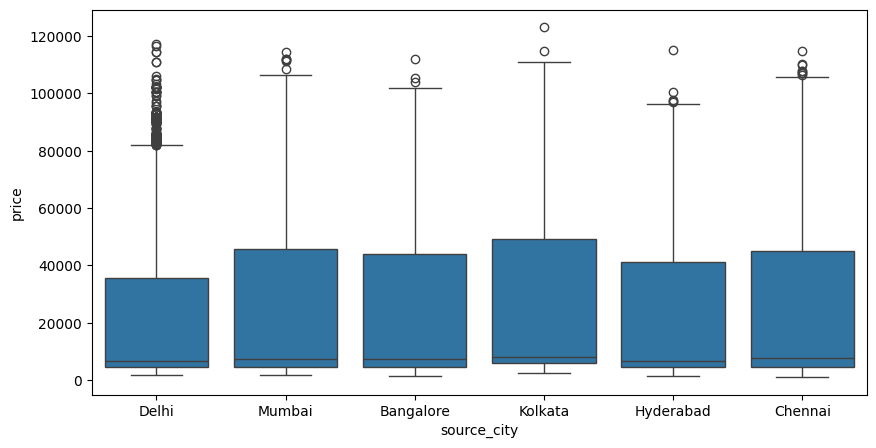

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(x=df["source_city"],y=df["price"], data=df)
plt.show()

1. Delhi: Shows the widest spread with many high-price outliers fare from delhi vary greatly
2. M,B,H,C: These cities have more moderate distributions

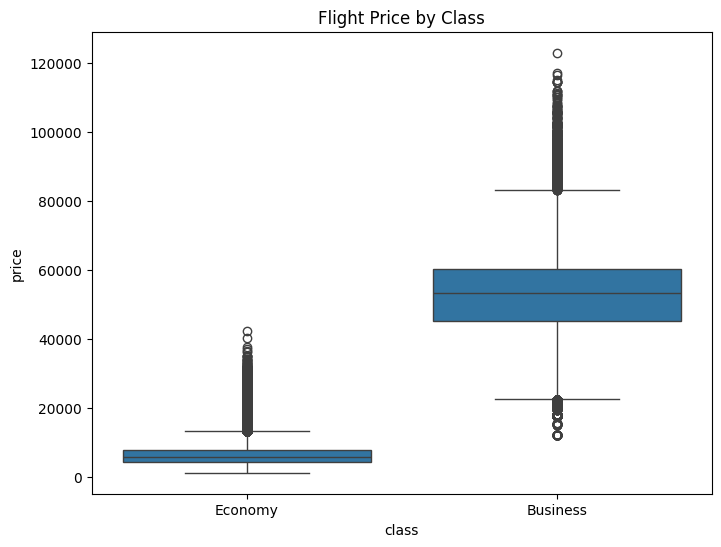

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='class',y='price',data=df)
plt.title('Flight Price by Class')
plt.show()

1. Business class: Much higher median prices, with a wider range and more variability

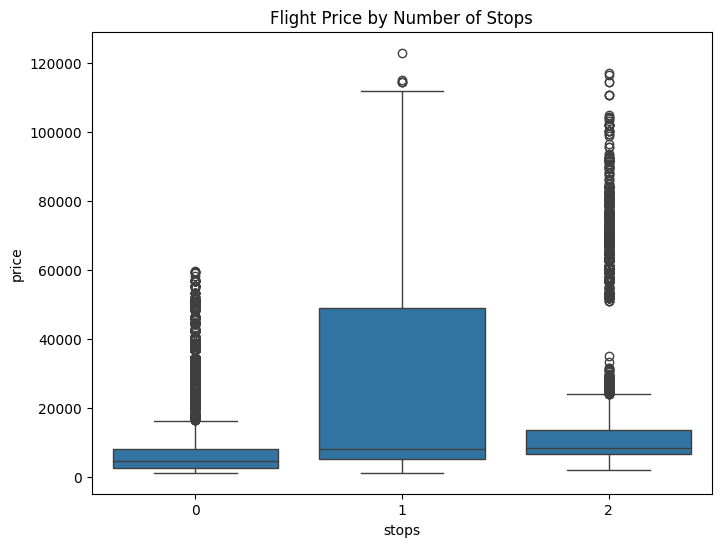

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='stops',y='price',data=df,)
plt.title('Flight Price by Number of Stops')
plt.show()

In [ ]:
# airasia have lower price and vistara is higher pricing

In [ ]:
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3-q1
lb = q1 - 1.5*iqr
ub = q3 + 1.5*iqr
print('q1 ->:',q1,'\n')
print('q3 ->:',q3,'\n')
print('iqr ->:',iqr,'\n')
print('Lower Bound -> :',lb,'\n')
print('Upper Bound -> :',ub,'\n')

price_outliers = df[(df['price'] < lb) |(df['price'] > ub)]
print("Price outliers:", len(price_outliers))

q1 ->: 4783.0 

q3 ->: 42521.0 

iqr ->: 37738.0 

Lower Bound -> : -51824.0 

Upper Bound -> : 99128.0 

Price outliers: 123


In [ ]:
df[df['price'] < lb]['price'].count()

np.int64(0)

In [ ]:
df[df['price'] > ub]['price'].count()

np.int64(123)

In [ ]:
df.head(2)

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,Delhi,Evening,0,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,Delhi,Early_Morning,0,Morning,Mumbai,Economy,2.33,1,5953


In [ ]:
df.select_dtypes('object').columns.to_list()

['airline',
 'source_city',
 'departure_time',
 'arrival_time',
 'destination_city',
 'class']

In [ ]:
cat_cols = ['airline','source_city',
 'departure_time',
 'arrival_time',
 'destination_city',
 'class']


label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

In [ ]:
df

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,4,2,2,0,5,5,1,2.17,1,5953
1,4,2,1,0,4,5,1,2.33,1,5953
2,0,2,1,0,1,5,1,2.17,1,5956
3,5,2,4,0,0,5,1,2.25,1,5955
4,5,2,4,0,4,5,1,2.33,1,5955
...,...,...,...,...,...,...,...,...,...,...
300148,5,1,4,1,2,3,0,10.08,49,69265
300149,5,1,0,1,5,3,0,10.42,49,77105
300150,5,1,1,1,5,3,0,13.83,49,79099
300151,5,1,1,1,2,3,0,10.00,49,81585


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  int64  
 1   source_city       300153 non-null  int64  
 2   departure_time    300153 non-null  int64  
 3   stops             300153 non-null  int64  
 4   arrival_time      300153 non-null  int64  
 5   destination_city  300153 non-null  int64  
 6   class             300153 non-null  int64  
 7   duration          300153 non-null  float64
 8   days_left         300153 non-null  int64  
 9   price             300153 non-null  int64  
dtypes: float64(1), int64(9)
memory usage: 22.9 MB


In [ ]:
df['airline'].unique()

array([4, 0, 5, 2, 3, 1])

In [ ]:
df.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,4,2,2,0,5,5,1,2.17,1,5953
1,4,2,1,0,4,5,1,2.33,1,5953
2,0,2,1,0,1,5,1,2.17,1,5956
3,5,2,4,0,0,5,1,2.25,1,5955
4,5,2,4,0,4,5,1,2.33,1,5955


In [ ]:
'''plt.figure(figsize=(12,8))
sns.pairplot(df)
plt.show()'''

'plt.figure(figsize=(12,8))\nsns.pairplot(df)\nplt.show()'

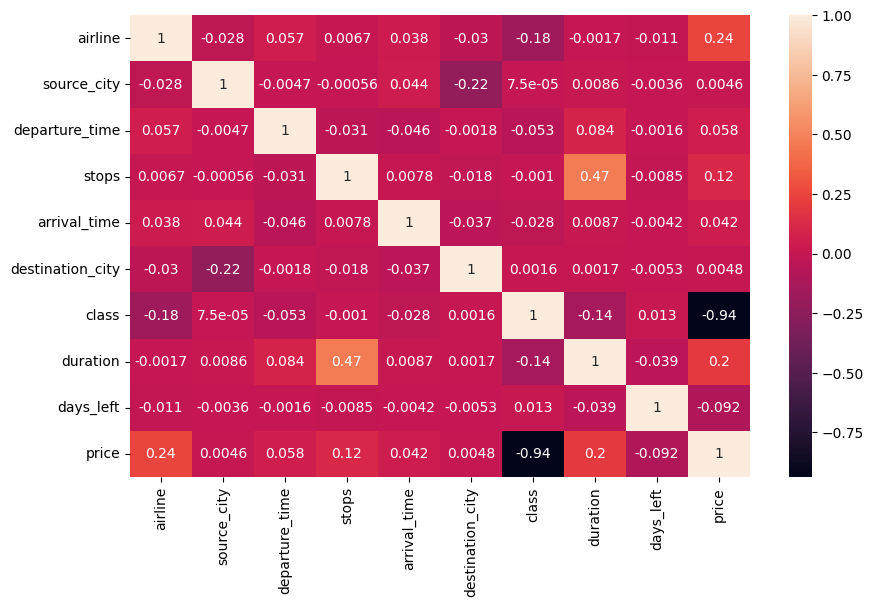

In [ ]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(),annot=True)
plt.show()

In [ ]:
x = df.drop(['price'],axis=1)
y = df['price']

In [ ]:
x

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left
0,4,2,2,0,5,5,1,2.17,1
1,4,2,1,0,4,5,1,2.33,1
2,0,2,1,0,1,5,1,2.17,1
3,5,2,4,0,0,5,1,2.25,1
4,5,2,4,0,4,5,1,2.33,1
...,...,...,...,...,...,...,...,...,...
300148,5,1,4,1,2,3,0,10.08,49
300149,5,1,0,1,5,3,0,10.42,49
300150,5,1,1,1,5,3,0,13.83,49
300151,5,1,1,1,2,3,0,10.00,49


In [ ]:
y

,price
0,5953
1,5953
2,5956
3,5955
4,5955
...,...
300148,69265
300149,77105
300150,79099
300151,81585


spliting into training and testing

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size= 0.25 , random_state= 42)

In [ ]:
x_train

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left
298245,5,1,4,1,0,3,0,26.50,7
210650,1,2,4,1,4,5,0,25.08,38
38033,1,2,4,1,4,1,1,25.92,20
270667,5,4,4,1,1,3,0,21.42,11
248464,5,0,1,1,2,2,0,10.25,47
...,...,...,...,...,...,...,...,...,...
119879,5,4,2,1,0,2,1,20.50,2
259178,5,0,5,1,5,1,0,25.42,7
131932,1,4,5,1,4,5,1,13.67,29
146867,2,4,0,1,5,3,1,8.33,39


In [ ]:
x_test

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left
27131,1,2,4,1,1,4,1,19.75,40
266857,5,4,4,1,5,5,0,9.83,42
141228,5,4,4,1,5,0,1,10.50,41
288329,5,1,5,1,4,2,0,14.50,14
97334,1,0,0,1,5,5,1,8.25,20
...,...,...,...,...,...,...,...,...,...
104184,1,0,2,1,2,4,1,24.25,12
93137,4,0,5,0,3,2,1,2.92,45
50649,5,5,2,1,0,2,1,17.33,39
277630,5,3,4,1,2,5,0,7.33,8


In [ ]:
x_train.shape,x_test.shape,y_train.shape,y_test.shape

((225114, 9), (75039, 9), (225114,), (75039,))

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [ ]:
# # Fit the scaler on TRAIN ONLY, then apply it to both — never fit on test data
x_train_scale = scaler.fit_transform(x_train)
x_test_scale = scaler.fit_transform(x_test)

In [ ]:
x_train_scale

array([[ 1.03201404, -0.9005278 ,  0.90354357, ..., -1.48754606,
         1.98757315, -1.40195025],
       [-1.14985272, -0.32953464,  0.90354357, ..., -1.48754606,
         1.7900826 ,  0.88235641],
       [-1.14985272, -0.32953464,  0.90354357, ...,  0.67224809,
         1.906908  , -0.4440152 ],
       ...,
       [-1.14985272,  0.81245168,  1.47396021, ...,  0.67224809,
         0.20320436,  0.2191706 ],
       [-0.60438603,  0.81245168, -1.37812299, ...,  0.67224809,
        -0.53947136,  0.95604372],
       [-1.14985272,  0.81245168, -1.37812299, ...,  0.67224809,
         1.10721037, -0.66507714]])

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

Linear Regression

In [ ]:
linear = LinearRegression()

In [ ]:
linear.fit(x_train_scale,y_train)


LinearRegression()

In [ ]:
y_pred = linear.predict(x_test_scale)

In [ ]:
y_pred

array([ 3980.84227159, 52882.96238174,  7234.46600938, ...,
        7447.50821739, 56494.71710498,    75.52495129])

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = math.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test,y_pred)
print("Mean Absolute Eror: ", mae)
print("Mean Squared Eror: ", mse)
print('RMSE:', rmse)
print("r2 score: ", r2)

Mean Absolute Eror:  4529.730574393808
Mean Squared Eror:  48204499.53887
RMSE: 6942.946027362592
r2 score:  0.9065112192032124


Decision Tree Regressor

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
regressor = DecisionTreeRegressor(max_depth=3)

In [ ]:
regressor.fit(x_train_scale, y_train)

DecisionTreeRegressor(max_depth=3)

In [ ]:
y_pred = regressor.predict(x_test_scale)

In [ ]:
y_pred

array([ 5477.28359176, 57898.26563064,  5477.28359176, ...,
        5477.28359176, 57898.26563064,  3152.91120111])

In [ ]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = math.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test,y_pred)
print("Mean Absolute Eror: ", mae)
print("Mean Squared Eror: ", mse)
print('RMSE:', rmse)
print("r2 score: ", r2)

Mean Absolute Eror:  3502.4771741724467
Mean Squared Eror:  34017534.80162278
RMSE: 5832.455297867509
r2 score:  0.9340257053856231


Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
RFC = RandomForestRegressor(n_estimators= 100,random_state=42)

In [ ]:
RFC.fit(x_train_scale, y_train)
y_pred = RFC.predict(x_test_scale)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = math.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test,y_pred)
print("Mean Absolute Eror: ", mae)
print("Mean Squared Eror: ", mse)
print('RMSE:', rmse)
print("r2 score: ", r2)



Mean Absolute Eror:  1295.6488176228254
Mean Squared Eror:  10232076.822568854
RMSE: 3198.7617639594314
r2 score:  0.9801557033822188


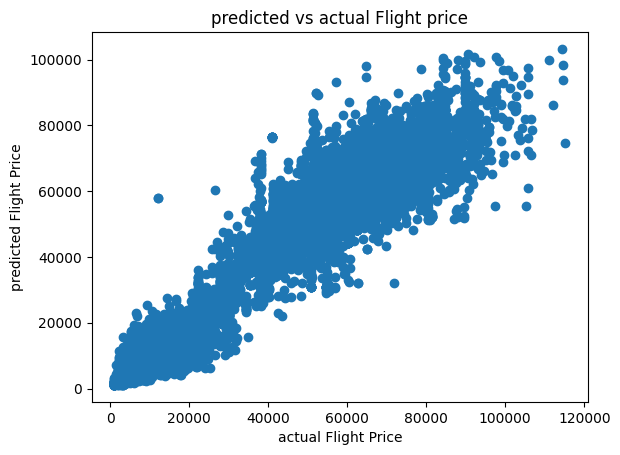

In [ ]:
plt.scatter(y_test,y_pred)
plt.xlabel('actual Flight Price')
plt.ylabel('predicted Flight Price')
plt.title('predicted vs actual Flight price')
plt.show()

In [ ]:
from sklearn.ensemble import ExtraTreesRegressor
selection = ExtraTreesRegressor()
selection.fit(x,y)

ExtraTreesRegressor()

In [ ]:
print(selection.feature_importances_)

[0.01135085 0.01024823 0.00507921 0.03213269 0.00535445 0.01051074
 0.88037117 0.02654633 0.01840633]


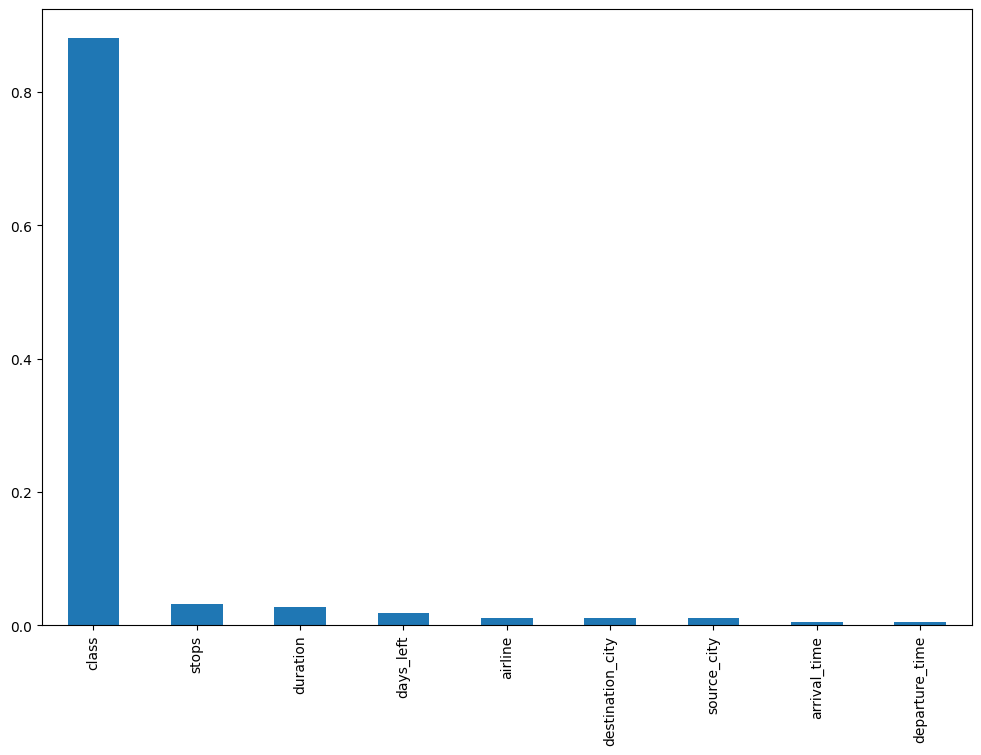

In [ ]:
plt.figure(figsize = (12,8))
feat_importances = pd.Series(selection.feature_importances_,index=x.columns)
feat_importances.nlargest(20).plot(kind= 'bar')
plt.show()

In [ ]:
x_train.columns

Index(['airline', 'source_city', 'departure_time', 'stops', 'arrival_time',
       'destination_city', 'class', 'duration', 'days_left'],
      dtype='object')

In [ ]:
df.head(20)

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,4,2,2,0,5,5,1,2.17,1,5953
1,4,2,1,0,4,5,1,2.33,1,5953
2,0,2,1,0,1,5,1,2.17,1,5956
3,5,2,4,0,0,5,1,2.25,1,5955
4,5,2,4,0,4,5,1,2.33,1,5955
5,5,2,4,0,0,5,1,2.33,1,5955
6,5,2,4,0,4,5,1,2.08,1,6060
7,5,2,0,0,2,5,1,2.17,1,6060
8,2,2,1,0,4,5,1,2.17,1,5954
9,2,2,0,0,2,5,1,2.25,1,5954


In [ ]:
#new_ticket = pd.DataFrame({'airline':['Vistara'],'source_city':['Mumbai'],'departure_time':['Early_Morning'],'stops':[1],'arrival_time':['Early_Morning'],'destination_city':['Delhi'],'class':['Business'],'duration':[12.25],'days_left':[2]})
new_ticket = pd.DataFrame({'airline':['SpiceJet'],'source_city':['Delhi'],'departure_time':['Evening'],'stops':['0'],'arrival_time':['Night'],'destination_city':['Mumbai'],'class':['Economy'],'duration':[2.17],'days_left':[1]})

In [ ]:
cat_cols_new = [
    'airline',
    'source_city',
    'departure_time',
    'arrival_time',
    'destination_city',
    'class'
]

for col in cat_cols_new:
    new_ticket[col] = label_encoders[col].transform(new_ticket[col].astype(str).values)

In [ ]:
new_ticket

,airline,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left
0,4,2,2,0,5,5,1,2.17,1


In [ ]:
new_ticket_scale = scaler.transform(new_ticket)

In [ ]:
predict_ticket_price = RFC.predict(new_ticket_scale)

In [ ]:
predict_ticket_price

array([9929.93])

In [ ]:
# Random Forest Model
#joblib.dump(RFC,'flight_pred_model.pkl')

In [ ]:
# scaler
#joblib.dump(scaler,'scaler.pkl')

In [ ]:
#labelEncoder
# joblib.dump(label_encoders,'label_encoder.pkl')

In [ ]:
#from google.colab import files
#files.download("flight_pred_model.pkl")
#files.download("scaler.pkl")
#files.download("label_encoder.pkl")
